<a href="https://colab.research.google.com/github/crjacinto/ML-IQ/blob/main/ML_IQ.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Introducción al Machine Learning en Ingeniería Química
## Taller práctico · Termodinámica de Procesos

**Objetivo:** construir modelos de regresión para predecir la potencia generada en turbinas a partir de datos de operación, y entender por qué la calidad de los datos y el criterio físico pesan más que el algoritmo.

**Datos utilizados**

1. `Datos_CH.csv`: turbina de vapor de extracción-condensación de un ingenio azucarero. Un registro por día (probablemente promedios diarios) durante la zafra 2025–2026.
2. `gt_2011.csv`: turbina de gas de una central de ciclo combinado en Turquía. Promedios horarios del año 2011, ordenados cronológicamente (UCI Machine Learning Repository).

**Estructura**

1. Colab y Python básico
2. Set 1: datos del ingenio
3. Set 2: turbina de gas (UCI)
4. Comparación con modelos termodinámicos
5. Conclusiones

## 1. Colab y Python básico

**Cómo usar este notebook**

- Una celda se ejecuta con `Shift + Enter` o con el botón ▶ a su izquierda.
- Las celdas deben ejecutarse **en orden**, de arriba hacia abajo: muchas usan variables definidas en celdas anteriores.
- Si algo falla de forma extraña, usa *Entorno de ejecución → Reiniciar sesión* y vuelve a ejecutar desde el inicio.
- Para guardar tus cambios usa *Archivo → Guardar una copia en Drive*.

In [1]:
# Librerías principales (todas vienen preinstaladas en Colab)
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt

# Modelos y herramientas de scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Semilla fija: así todos obtenemos los mismos resultados
SEMILLA = 42

# Tamaño por defecto de las figuras
plt.rcParams["figure.figsize"] = (10, 4)

print(f"numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")

### Ubicación de los datos

Los archivos están en un repositorio de GitHub. Si la descarga falla, puedes subirlos manualmente: en el panel izquierdo de Colab, haz clic en el ícono de carpeta → *Subir*, y reemplaza la URL de la siguiente celda por el nombre de archivo (`"Datos_CH.csv"`).

In [2]:
URL_BASE = "https://raw.githubusercontent.com/crjacinto/ML-IQ/main/data/"

URL_INGENIO = URL_BASE + "Datos_CH.csv"

### Funciones auxiliares

Definimos dos funciones que usaremos varias veces durante el taller: una para calcular las métricas de error y otra para comparar gráficamente valores reales y predichos.

- **MAE** (error absoluto medio): error promedio, en las mismas unidades que la variable.
- **RMSE** (raíz del error cuadrático medio): similar al MAE, pero penaliza más los errores grandes.
- **R²**: fracción de la variabilidad de los datos que explica el modelo (1 = perfecto).

In [3]:
def evaluar_modelo(y_real, y_pred, nombre="modelo"):
    """Calcula y muestra MAE, RMSE y R² de un modelo."""
    mae = mean_absolute_error(y_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    r2 = r2_score(y_real, y_pred)
    print(f"{nombre}: MAE = {mae:.2f} | RMSE = {rmse:.2f} | R² = {r2:.3f}")

def graficar_real_vs_pred(y_real, y_pred, titulo="", unidad=""):
    """Grafica predicción vs. valor real; la diagonal es la predicción perfecta."""
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.scatter(y_real, y_pred, alpha=0.6)
    limites = [min(y_real.min(), y_pred.min()), max(y_real.max(), y_pred.max())]
    ax.plot(limites, limites, "k--", label="Predicción perfecta")
    ax.set_xlabel(f"Valor real {unidad}")
    ax.set_ylabel(f"Valor predicho {unidad}")
    ax.set_title(titulo)
    ax.legend()
    plt.show()

### Mini repaso de pandas

`pandas` organiza los datos en tablas llamadas **DataFrames**, similares a una hoja de Excel: cada columna es una variable y cada fila un registro. Hagamos un primer contacto con los datos del ingenio.

In [4]:
# Lectura directa, sin ninguna opción adicional
df_crudo = pd.read_csv(URL_INGENIO)

# Primeras 5 filas
df_crudo.head()

,Fecha,Presion_Vapor[kg/cm2],TemperaturaVapor_A[C],TemperaturaVapor_B[C],FlujoIn[Ton/h],Potencia[Mw],FlujoExtraccion[Ton/h],PresionExtraccion[kg/cm2],TemperaturaExtraccion[C]
0,11/10/2025 0:00,73.600433,417.686401,415.900604,72.191902,18.358021,11.69844,0.542326,81.928032
1,11/11/2025 0:00,5.391518,282.782013,283.094696,0.000000,0.000000,0.00000,0.000000,38.872070
2,11/12/2025 0:00,3.159722,243.750000,245.138901,0.000000,0.000000,0.00000,0.000000,34.201389
3,11/13/2025 0:00,3.159722,243.750000,245.138901,0.000000,0.000000,0.00000,0.000000,34.201389
4,11/14/2025 0:00,3.159722,243.750000,245.138901,0.000000,0.000000,0.00000,0.000000,34.201389


In [5]:
# Tipo de dato y cantidad de valores no nulos por columna
df_crudo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 191 entries, 0 to 190
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Fecha                      191 non-null    object 
 1   Presion_Vapor[kg/cm2]      187 non-null    float64
 2   TemperaturaVapor_A[C]      187 non-null    float64
 3   TemperaturaVapor_B[C]      187 non-null    float64
 4   FlujoIn[Ton/h]             187 non-null    float64
 5   Potencia[Mw]               187 non-null    float64
 6   FlujoExtraccion[Ton/h]     187 non-null    float64
 7   PresionExtraccion[kg/cm2]  187 non-null    float64
 8   TemperaturaExtraccion[C]   187 non-null    float64
dtypes: float64(8), object(1)
memory usage: 13.6+ KB


**Observa:** la columna `Fecha` aparece como `object` (texto), no como fecha. Además, todas las variables numéricas tienen menos valores no nulos que el total de filas: hay datos faltantes. Lo corregiremos en la Sección 2.

In [6]:
# Estadísticas descriptivas (.T transpone la tabla para leerla mejor)
df_crudo.describe().T

,count,mean,std,min,25%,50%,75%,max
Presion_Vapor[kg/cm2],187.0,100.529002,26.788213,0.000320,108.187752,108.349197,108.997150,109.512199
TemperaturaVapor_A[C],187.0,517.596176,82.435868,23.271931,539.913940,541.823303,543.010651,549.091797
TemperaturaVapor_B[C],187.0,517.103284,81.850559,27.617910,539.396149,541.099182,542.317841,548.513489
FlujoIn[Ton/h],187.0,206.064842,59.584987,0.000000,224.509300,225.908295,226.489502,227.548004
Potencia[Mw],187.0,46.903484,13.837156,0.000000,49.293470,49.981251,50.729065,59.613960
FlujoExtraccion[Ton/h],187.0,110.002002,53.802422,0.000000,121.763802,138.085693,140.793404,147.159195
PresionExtraccion[kg/cm2],187.0,1.439913,0.427645,0.000000,1.528453,1.541199,1.545273,1.896412
TemperaturaExtraccion[C],187.0,118.934306,23.688081,27.729080,125.587200,125.751999,125.845303,131.077805


In [7]:
# Seleccionar una columna
potencia = df_crudo["Potencia[Mw]"]

# Filtrar filas que cumplen una condición
dias_alta_potencia = df_crudo[df_crudo["Potencia[Mw]"] > 40]
print(f"Días con potencia mayor a 40 MW: {len(dias_alta_potencia)} de {len(df_crudo)}")

Días con potencia mayor a 40 MW: 169 de 191


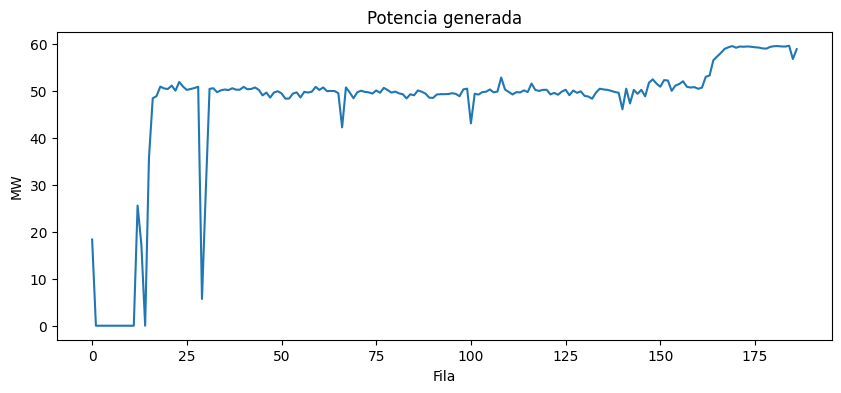

In [8]:
# Gráfico rápido de una columna
df_crudo["Potencia[Mw]"].plot(title="Potencia generada", ylabel="MW", xlabel="Fila")
plt.show()

## 2. Set 1: datos del ingenio azucarero

Turbina de vapor de **extracción-condensación**: una parte del vapor se extrae a baja presión para el proceso (calentadores, evaporadores) y el resto se expande hasta el condensador. El ingenio vende electricidad y almacena bagazo para seguir generando una vez terminada la molienda.

| Variable | Descripción | Unidad |
|---|---|---|
| `P_vapor` | Presión del vapor a la entrada (manométrica) | kg/cm² |
| `T_vapor_A`, `T_vapor_B` | Temperatura del vapor a la entrada (dos sensores) | °C |
| `F_in` | Flujo de vapor a la entrada | t/h |
| `Potencia` | Potencia eléctrica generada | MW |
| `F_ext` | Flujo de vapor de extracción | t/h |
| `P_ext` | Presión de extracción (manométrica) | kg/cm² |
| `T_ext` | Temperatura de extracción | °C |

In [9]:
# Lectura con opciones explícitas.
# pandas ya reconoce "#N/A" como faltante por defecto; lo declaramos igual para dejarlo documentado.
df = pd.read_csv(URL_INGENIO, na_values=["#N/A"])

# Convertir la fecha de texto a formato fecha (mes/día/año) y usarla como índice
df["Fecha"] = pd.to_datetime(df["Fecha"], format="%m/%d/%Y %H:%M")
df = df.set_index("Fecha")

# Nombres cortos para trabajar más cómodamente
nombres = {
    "Presion_Vapor[kg/cm2]": "P_vapor",
    "TemperaturaVapor_A[C]": "T_vapor_A",
    "TemperaturaVapor_B[C]": "T_vapor_B",
    "FlujoIn[Ton/h]": "F_in",
    "Potencia[Mw]": "Potencia",
    "FlujoExtraccion[Ton/h]": "F_ext",
    "PresionExtraccion[kg/cm2]": "P_ext",
    "TemperaturaExtraccion[C]": "T_ext",
}
df = df.rename(columns=nombres)

print(f"Periodo: {df.index.min().date()} a {df.index.max().date()} ({len(df)} registros)")
df.info()

Periodo: 2025-11-10 a 2026-05-19 (191 registros)
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 191 entries, 2025-11-10 to 2026-05-19
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   P_vapor    187 non-null    float64
 1   T_vapor_A  187 non-null    float64
 2   T_vapor_B  187 non-null    float64
 3   F_in       187 non-null    float64
 4   Potencia   187 non-null    float64
 5   F_ext      187 non-null    float64
 6   P_ext      187 non-null    float64
 7   T_ext      187 non-null    float64
dtypes: float64(8)
memory usage: 13.4 KB


In [10]:
# ¿Dónde están los datos faltantes?
df[df.isna().any(axis=1)]

,P_vapor,T_vapor_A,T_vapor_B,F_in,Potencia,F_ext,P_ext,T_ext
Fecha,,,,,,,,
2026-05-16,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-05-17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-05-18,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-05-19,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 2.1 Mirar los datos antes de modelar

Antes de entrenar cualquier modelo, **siempre** hay que graficar los datos en el tiempo.

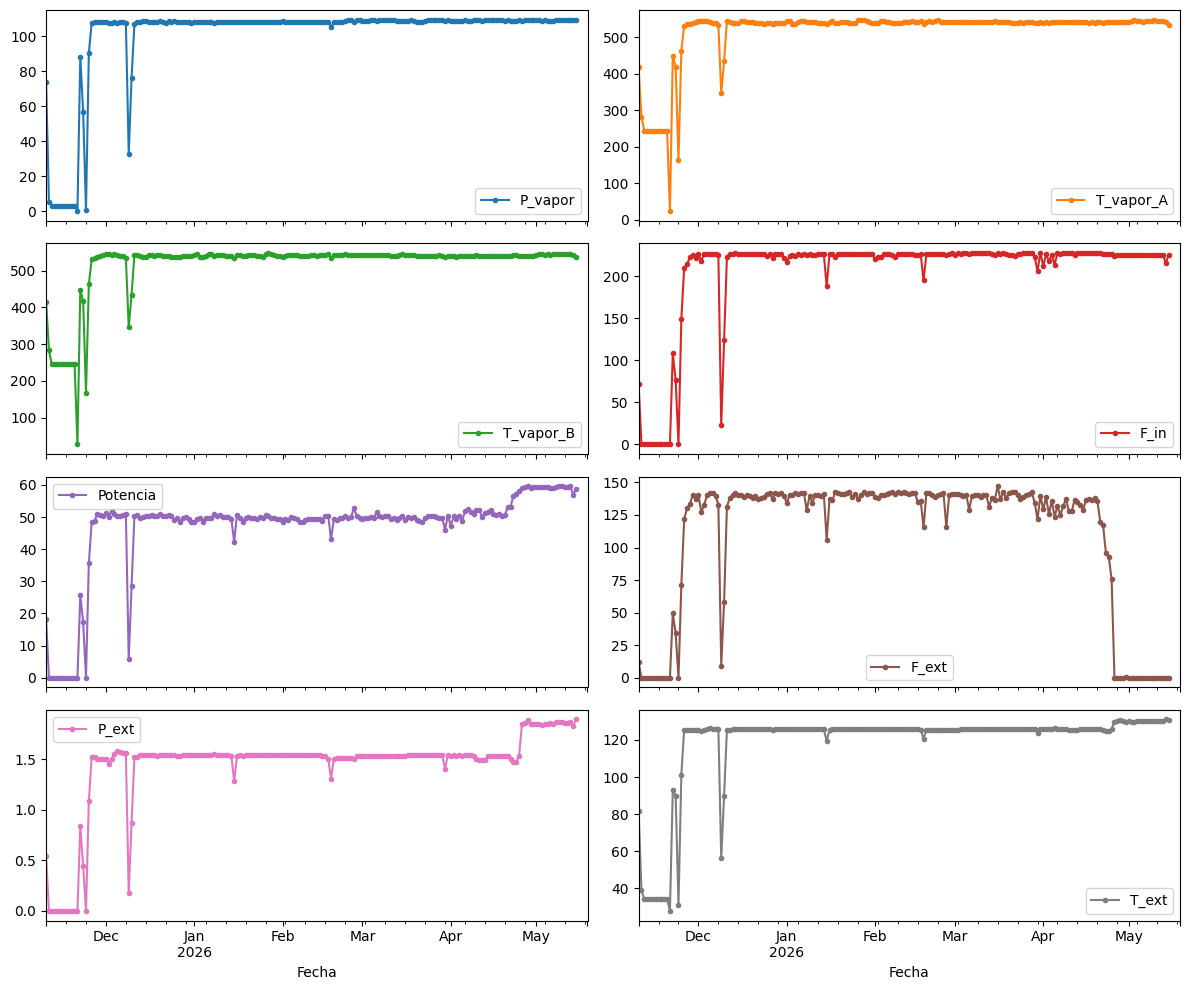

In [11]:
df.plot(subplots=True, layout=(4, 2), figsize=(12, 10), sharex=True, marker=".", linestyle="-")
plt.tight_layout()
plt.show()

In [12]:
# Filas idénticas entre sí (sin contar los faltantes): señal de valores congelados
filas_completas = df.dropna()
congelados = filas_completas[filas_completas.duplicated(keep=False)]
congelados

,P_vapor,T_vapor_A,T_vapor_B,F_in,Potencia,F_ext,P_ext,T_ext
Fecha,,,,,,,,
2025-11-12,3.159722,243.75,245.138901,0.0,0.0,0.0,0.0,34.201389
2025-11-13,3.159722,243.75,245.138901,0.0,0.0,0.0,0.0,34.201389
2025-11-14,3.159722,243.75,245.138901,0.0,0.0,0.0,0.0,34.201389
2025-11-15,3.159722,243.75,245.138901,0.0,0.0,0.0,0.0,34.201389
2025-11-16,3.159722,243.75,245.138901,0.0,0.0,0.0,0.0,34.201389
2025-11-17,3.159722,243.75,245.138901,0.0,0.0,0.0,0.0,34.201389
2025-11-18,3.159722,243.75,245.138901,0.0,0.0,0.0,0.0,34.201389
2025-11-19,3.159722,243.75,245.138901,0.0,0.0,0.0,0.0,34.201389
2025-11-20,3.159722,243.75,245.138901,0.0,0.0,0.0,0.0,34.201389


**¿Qué observamos?**

- **Arranque de zafra (10–25 de noviembre):** un día de operación, una parada de 11 días y una rampa de arranque. Los flujos de esos días no representan operación normal.
- **Valores congelados (12–20 de noviembre):** filas idénticas hasta el último decimal. Ningún sensor real repite exactamente el mismo valor 9 días seguidos: el sistema de registro mantuvo el último dato.
- **Paradas**: días puntuales con flujo y potencia menores. Algunas son casi totales (9–10 de diciembre) y otras parciales (p. ej. 15 de enero). Como cada dato es un promedio diario, una parada de algunas horas baja el promedio.
- **Cambio de régimen (desde fines de abril):** la extracción cae a cero y la potencia **sube** a ~59 MW con el mismo flujo de entrada. Terminó la molienda, ya no se necesita vapor de proceso y todo el vapor se expande hasta el condensador, quemando bagazo almacenado.
- **Datos faltantes (16–19 de mayo).**

Nada de esto se ve en una tabla de estadísticas descriptivas.

### 2.2 El modelo ingenuo

Veamos qué pasa si ignoramos todo lo anterior: eliminamos solo los faltantes, usamos todas las variables y separamos los datos al azar.

Modelo ingenuo: MAE = 0.52 | RMSE = 0.76 | R² = 0.997


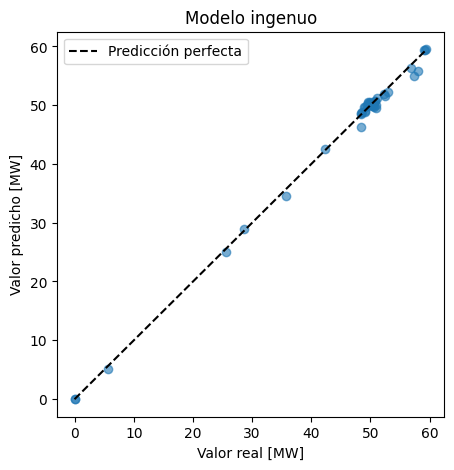

In [13]:
df_ingenuo = df.dropna()
X = df_ingenuo.drop(columns="Potencia")
y = df_ingenuo["Potencia"]

# 75 % para entrenar y 25 % para probar, elegidos al azar
X_ent, X_prueba, y_ent, y_prueba = train_test_split(X, y, test_size=0.25, random_state=SEMILLA)

modelo_ingenuo = LinearRegression().fit(X_ent, y_ent)
pred_ingenuo = modelo_ingenuo.predict(X_prueba)

evaluar_modelo(y_prueba, pred_ingenuo, "Modelo ingenuo")
graficar_real_vs_pred(y_prueba, pred_ingenuo, "Modelo ingenuo", "[MW]")

In [14]:
# Mismo modelo ingenuo (datos crudos, todas las variables), pero entrenando con el pasado
# y probando con el futuro (mismo corte que usaremos en la sección 2.5)
ing_ent = df_ingenuo.loc[:"2026-03-31"]
ing_prueba = df_ingenuo.loc["2026-04-01":]

modelo_ing_t = LinearRegression().fit(ing_ent.drop(columns="Potencia"), ing_ent["Potencia"])
pred_ing_t = modelo_ing_t.predict(ing_prueba.drop(columns="Potencia"))

evaluar_modelo(ing_prueba["Potencia"], pred_ing_t, "Ingenuo, separación temporal")

Ingenuo, separación temporal: MAE = 5.55 | RMSE = 8.09 | R² = -2.818


**Discusión**

- Con separación aleatoria el modelo ingenuo parece excelente (R² ≈ 1). Incluso los días apagados son coherentes con la física: sin flujo no hay potencia.
- El R² ≈ 1 también está inflado por los días de arranque (potencia ≈ 0): amplían mucho la variabilidad total, y un modelo que los acierta obtiene un R² alto casi automáticamente. El MAE, en MW, es más fácil de interpretar.
- Pero la separación aleatoria permite que el modelo vea días del régimen sin extracción durante el entrenamiento: solo interpola.
- Con separación temporal, el mismo modelo tiene un R² **negativo**: predice peor que usar simplemente el promedio. En el régimen nuevo, `P_ext` y `T_ext` toman valores que nunca vio (miden una línea sin flujo), y el modelo, que no sabe nada de física, les da un peso que ya no tiene sentido.

**Lección:** la forma de evaluar un modelo puede cambiar completamente la conclusión. En procesos que evolucionan en el tiempo, la separación aleatoria suele ser demasiado optimista.

### 2.3 Limpieza con criterio físico

Definimos qué es "operación normal" con un criterio del proceso, no estadístico: un flujo de vapor de entrada mínimo. Esto elimina de una vez las paradas totales, el arranque y los valores congelados (que tienen flujo cero). Las paradas parciales se conservan (ver la nota más abajo).

Además, los dos sensores de temperatura de entrada miden lo mismo: los promediaremos.

In [15]:
UMBRAL_FLUJO = 150  # t/h; por debajo consideramos que la planta no opera de forma estable

df_limpio = df.dropna().copy()
df_limpio = df_limpio[df_limpio["F_in"] >= UMBRAL_FLUJO]

eliminados = df.index.difference(df_limpio.index)
print(f"Registros originales: {len(df)} | después de limpiar: {len(df_limpio)}")
print("Fechas eliminadas:", list(eliminados.strftime("%d/%m/%Y")))

Registros originales: 191 | después de limpiar: 169
Fechas eliminadas: ['10/11/2025', '11/11/2025', '12/11/2025', '13/11/2025', '14/11/2025', '15/11/2025', '16/11/2025', '17/11/2025', '18/11/2025', '19/11/2025', '20/11/2025', '21/11/2025', '22/11/2025', '23/11/2025', '24/11/2025', '25/11/2025', '09/12/2025', '10/12/2025', '16/05/2026', '17/05/2026', '18/05/2026', '19/05/2026']


In [16]:
# ¿Qué tan parecidos son los dos sensores de temperatura?
diferencia_T = df_limpio["T_vapor_A"] - df_limpio["T_vapor_B"]
print(diferencia_T.describe())

df_limpio["T_vapor"] = (df_limpio["T_vapor_A"] + df_limpio["T_vapor_B"]) / 2

count    169.000000
mean       0.623034
std        0.189468
min       -1.215332
25%        0.544250
50%        0.634766
75%        0.703613
max        1.395935
dtype: float64


**Ejercicio 1:** cambia `UMBRAL_FLUJO` a 100, 200 y 220 t/h y vuelve a ejecutar las dos celdas anteriores. ¿Cuántos datos sobreviven en cada caso? ¿Qué días se pierden y tiene sentido físico eliminarlos?

**Nota:** los días con paradas parciales (p. ej. 15 de enero) se conservan. Flujo y potencia son variables **extensivas**: su promedio diario mantiene la relación de balance de energía. En cambio, promediar presiones y temperaturas (variables **intensivas**) de horas en operación y horas paradas da un estado termodinámico que nunca existió.

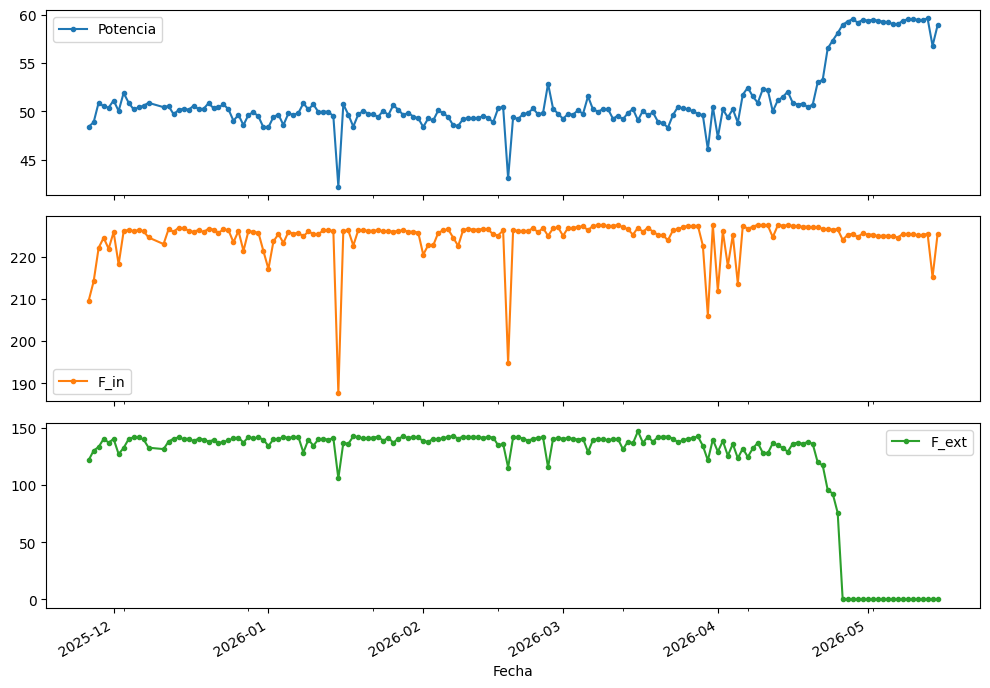

In [17]:
df_limpio[["Potencia", "F_in", "F_ext"]].plot(subplots=True, figsize=(10, 7), sharex=True, marker=".")
plt.tight_layout()
plt.show()

### 2.4 ¿Qué variables aportan información?

In [18]:
columnas = ["P_vapor", "T_vapor", "F_in", "F_ext", "P_ext", "T_ext", "Potencia"]

# El CV solo tiene sentido en escalas absolutas: presión absoluta y temperatura en K
absolutas = df_limpio[columnas].copy()
for c in ["P_vapor", "P_ext"]:
    absolutas[c] = absolutas[c] + 1.033  # kg/cm² abs, suponiendo 1 atm
for c in ["T_vapor", "T_ext"]:
    absolutas[c] = absolutas[c] + 273.15  # K

variacion = (absolutas.std() / absolutas.mean() * 100).round(1)
variacion.to_frame("Coef. de variación [%]")

,Coef. de variación [%]
P_vapor,0.5
T_vapor,0.5
F_in,2.2
F_ext,37.5
P_ext,7.1
T_ext,1.3
Potencia,6.6


**Ojo**: la variación de F_ext, P_ext y Potencia está dominada por el cambio de régimen de fines de abril, no por la operación normal.

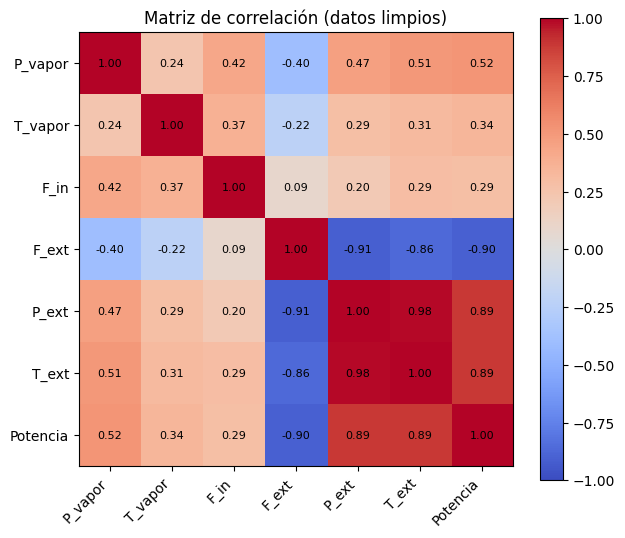

In [19]:
correlacion = df_limpio[columnas].corr()

fig, ax = plt.subplots(figsize=(7, 6))
imagen = ax.imshow(correlacion, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(columnas)), columnas, rotation=45, ha="right")
ax.set_yticks(range(len(columnas)), columnas)
for i in range(len(columnas)):
    for j in range(len(columnas)):
        ax.text(j, i, f"{correlacion.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(imagen)
ax.set_title("Matriz de correlación (datos limpios)")
plt.show()

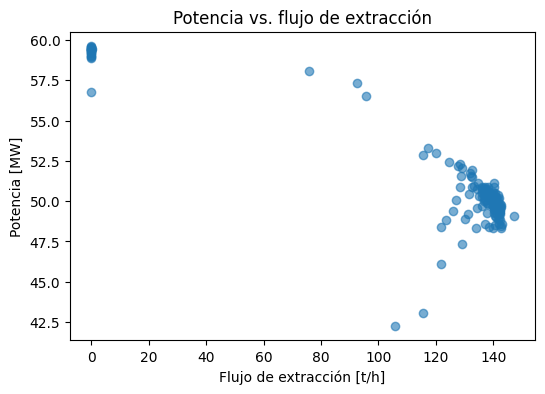

In [20]:
plt.figure(figsize=(6, 4))
plt.scatter(df_limpio["F_ext"], df_limpio["Potencia"], alpha=0.6)
plt.xlabel("Flujo de extracción [t/h]")
plt.ylabel("Potencia [MW]")
plt.title("Potencia vs. flujo de extracción")
plt.show()

**Discusión**

- Presión y temperatura de entrada son **físicamente clave**, pero en operación normal casi no varían (coeficiente de variación muy bajo). Una variable que no cambia no puede explicar los cambios de la potencia: aporta poca información **estadística**.
- La potencia depende sobre todo de cómo se reparte el vapor: el vapor extraído no se expande hasta el condensador y produce menos trabajo. Por eso, a flujo de entrada casi constante, **más extracción implica menos potencia**.
- `P_ext` y `T_ext` están casi perfectamente correlacionadas (0.98) por termodinámica: el vapor de extracción está prácticamente saturado, así que `T_ext ≈ T_sat(P_ext)` y no aporta información nueva. Cuando la extracción es cero, su lectura cambia de significado (presión de la etapa o de una línea sin flujo, según dónde esté el sensor): no sirven para extrapolar.

Importante: estas correlaciones se calcularon con todos los datos, incluidos abril y mayo, y están dominadas por los dos grupos que se ven en el gráfico. La elección de `F_in` y `F_ext` se justifica por el balance de energía, no por la correlación.

Usaremos entonces `F_in` y `F_ext` como variables de entrada.

### 2.5 Separación temporal: ¿qué pasa con el régimen nuevo?

En un proceso real, el modelo se entrena con el pasado y se usa en el futuro. Entrenaremos con los datos hasta marzo y probaremos con abril y mayo, cuando ocurre el cambio de régimen.

In [21]:
FECHA_CORTE = "2026-03-31"
variables = ["F_in", "F_ext"]

entrenamiento = df_limpio.loc[:FECHA_CORTE]
prueba = df_limpio.loc[df_limpio.index > FECHA_CORTE]

print(f"Entrenamiento: {len(entrenamiento)} días | Prueba: {len(prueba)} días")
print(f"F_ext en entrenamiento: {entrenamiento['F_ext'].min():.1f} a {entrenamiento['F_ext'].max():.1f} t/h")
print(f"F_ext en prueba:        {prueba['F_ext'].min():.1f} a {prueba['F_ext'].max():.1f} t/h")

Entrenamiento: 124 días | Prueba: 45 días
F_ext en entrenamiento: 105.9 a 147.2 t/h
F_ext en prueba:        0.0 a 138.6 t/h


In [22]:
modelo_lineal = LinearRegression().fit(entrenamiento[variables], entrenamiento["Potencia"])
modelo_rf = RandomForestRegressor(n_estimators=200, random_state=SEMILLA).fit(
    entrenamiento[variables], entrenamiento["Potencia"]
)

pred_lineal = modelo_lineal.predict(prueba[variables])
pred_rf = modelo_rf.predict(prueba[variables])

evaluar_modelo(prueba["Potencia"], pred_lineal, "Regresión lineal")
evaluar_modelo(prueba["Potencia"], pred_rf, "Random forest")

Regresión lineal: MAE = 4.73 | RMSE = 6.97 | R² = -1.833
Random forest: MAE = 5.01 | RMSE = 6.43 | R² = -1.414


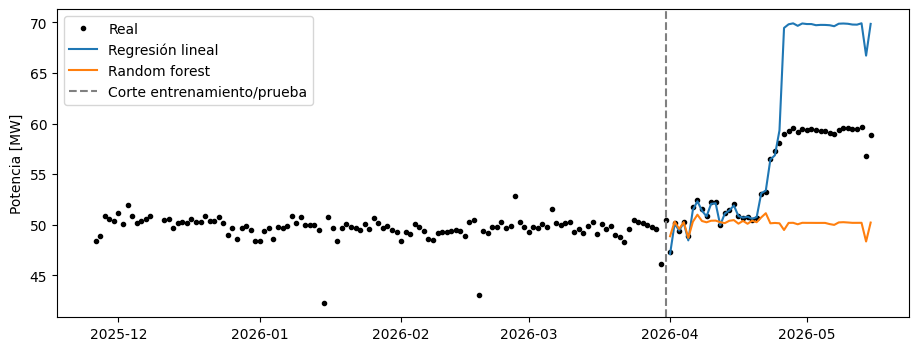

In [23]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df_limpio.index, df_limpio["Potencia"], "k.", label="Real")
ax.plot(prueba.index, pred_lineal, "-", label="Regresión lineal")
ax.plot(prueba.index, pred_rf, "-", label="Random forest")
ax.axvline(pd.Timestamp(FECHA_CORTE), color="gray", linestyle="--", label="Corte entrenamiento/prueba")
ax.set_ylabel("Potencia [MW]")
ax.legend()
plt.show()

In [46]:
# Error separado por régimen dentro del periodo de prueba
con_ext = (prueba["F_ext"] > 50).to_numpy()
for nombre, pred in [("Regresión lineal", pred_lineal), ("Random forest", pred_rf)]:
    evaluar_modelo(prueba["Potencia"][con_ext], pred[con_ext], f"{nombre} · con extracción")
    evaluar_modelo(prueba["Potencia"][~con_ext], pred[~con_ext], f"{nombre} · sin extracción")

Regresión lineal · con extracción: MAE = 0.17 | RMSE = 0.30 | R² = 0.985
Regresión lineal · sin extracción: MAE = 10.44 | RMSE = 10.44 | R² = -313.287
Random forest · con extracción: MAE = 1.70 | RMSE = 2.73 | R² = -0.264
Random forest · sin extracción: MAE = 9.15 | RMSE = 9.15 | R² = -240.230


In [24]:
# Interpretación física de los coeficientes del modelo lineal.
# 1 MW/(t/h) equivale a 3600 kJ/kg: cada coeficiente es un "salto de entalpía efectivo".
for nombre, coef in zip(variables, modelo_lineal.coef_):
    print(f"{nombre}: {coef:.4f} MW/(t/h)  ->  {coef * 3600:.0f} kJ/kg")
print(f"Intercepto: {modelo_lineal.intercept_:.2f} MW")

F_in: 0.3096 MW/(t/h)  ->  1115 kJ/kg
F_ext: -0.1440 MW/(t/h)  ->  -519 kJ/kg
Intercepto: 0.10 MW


**Discusión**

- El random forest **no puede extrapolar**: sus predicciones son promedios de datos de entrenamiento, así que nunca predice una potencia mayor a la que ya vio. Cuando la extracción cae a cero, se queda "atascado".
- La regresión lineal reproduce la estructura del balance de energía, P ≈ a·F_in − b·F_ext, y por eso predice correctamente que la potencia sube cuando la extracción cae a cero. Pero sobreestima la magnitud en unos 10 MW: el coeficiente de `F_in` está mal determinado, porque `F_in` casi no varía durante el entrenamiento. Ningún modelo es bueno en el régimen nuevo: el random forest no detecta el cambio y la regresión lo detecta pero exagera su magnitud.
- Los coeficientes tienen sentido físico: el de `F_in` se relaciona con el salto de entalpía desde la entrada hasta el condensador, y el de `F_ext` con la diferencia entre la entalpía de extracción y la del condensador. Compáralos con los valores de tablas de vapor (Sección 4).

**Pregunta para pensar:** cambia `FECHA_CORTE` a `"2026-04-28"`, para que el entrenamiento incluya algunos días sin extracción. ¿Cómo cambia el random forest?

### Conclusiones del Set 1

1. Graficar los datos en el tiempo revela problemas que las estadísticas no muestran.
2. Un R² alto puede ser engañoso si los datos mezclan estados que no son el proceso real.
3. La limpieza debe basarse en criterios físicos y del proceso.
4. Con pocos datos y una ventana de operación estrecha, un modelo con estructura física captura la tendencia fuera del rango de entrenamiento, pero no garantiza la magnitud: extrapolar siempre es riesgoso.
5. El modelo solo es válido en las condiciones en que fue entrenado: otra presión o temperatura de entrada no está representada en estos datos.

## 3. Set 2: turbina de gas (UCI)

Datos de una turbina de gas de una central de ciclo combinado en Turquía: 11 variables promediadas por hora durante 2011, ordenadas cronológicamente (las fechas no están incluidas).

**Importante:** este es un ciclo **Brayton** (aire comprimido, combustión y expansión de gases), no un ciclo de vapor como en el Set 1.

| Variable | Descripción | Unidad |
|---|---|---|
| `AT` | Temperatura ambiente | °C |
| `AP` | Presión ambiente | mbar |
| `AH` | Humedad relativa ambiente | % |
| `AFDP` | Caída de presión en el filtro de aire | mbar |
| `GTEP` | Presión de escape de la turbina | mbar |
| `TIT` | Temperatura de entrada a la turbina | °C |
| `TAT` | Temperatura de salida de la turbina | °C |
| `TEY` | Energía generada por hora (equivale a potencia media) | MW |
| `CDP` | Presión de descarga del compresor | bar* |
| `CO`, `NOX` | Emisiones de monóxido de carbono y óxidos de nitrógeno | mg/m³ |

\* La fuente original indica mbar, pero valores de ~12 solo tienen sentido físico en bar: corresponden a la relación de compresión típica de una turbina de gas. **Revisar las unidades también es parte del análisis de datos.**

In [25]:
ARCHIVO_TURBINA = "gt_2011.csv"

df_gt = pd.read_csv(URL_BASE + ARCHIVO_TURBINA)
df_gt.index.name = "Hora"  # el orden de las filas es cronológico: usamos el índice como tiempo

print(f"{len(df_gt)} registros horarios (~{len(df_gt) / 24:.0f} días)")
df_gt.describe().T

7411 registros horarios (~309 días)


,count,mean,std,min,25%,50%,75%,max
AT,7411.0,17.112261,7.428307,2.116300,10.992000,16.3660,23.34450,34.5320
AP,7411.0,1014.167883,6.293003,995.790000,1009.800000,1013.6000,1018.10000,1034.2000
AH,7411.0,79.174989,13.465898,34.493000,70.428500,82.1290,89.77800,100.1700
AFDP,7411.0,4.090755,0.661865,2.758400,3.644750,4.0263,4.48035,7.3189
GTEP,7411.0,25.663721,4.325835,17.878000,23.364500,24.7700,29.87950,36.0030
TIT,7411.0,1084.733909,16.134972,1000.800000,1082.500000,1088.0000,1099.80000,1100.6000
TAT,7411.0,544.503170,8.288471,512.450000,538.560000,549.8600,550.04000,550.6100
TEY,7411.0,135.745675,16.209187,100.170000,130.745000,133.8100,148.32500,170.0000
CDP,7411.0,12.207578,1.146561,9.904400,11.684000,12.0080,13.25700,14.8510
CO,7411.0,1.572486,1.845442,0.000388,0.726405,1.1557,1.75460,43.6220


**Observa:** no hay datos faltantes, pero un año tiene 8760 horas: faltan horas (probablemente paradas o datos descartados). Además, la humedad relativa supera el 100 % en algunos registros, algo físicamente imposible que indica un error o saturación del sensor.

### 3.1 Calidad de los datos en el tiempo

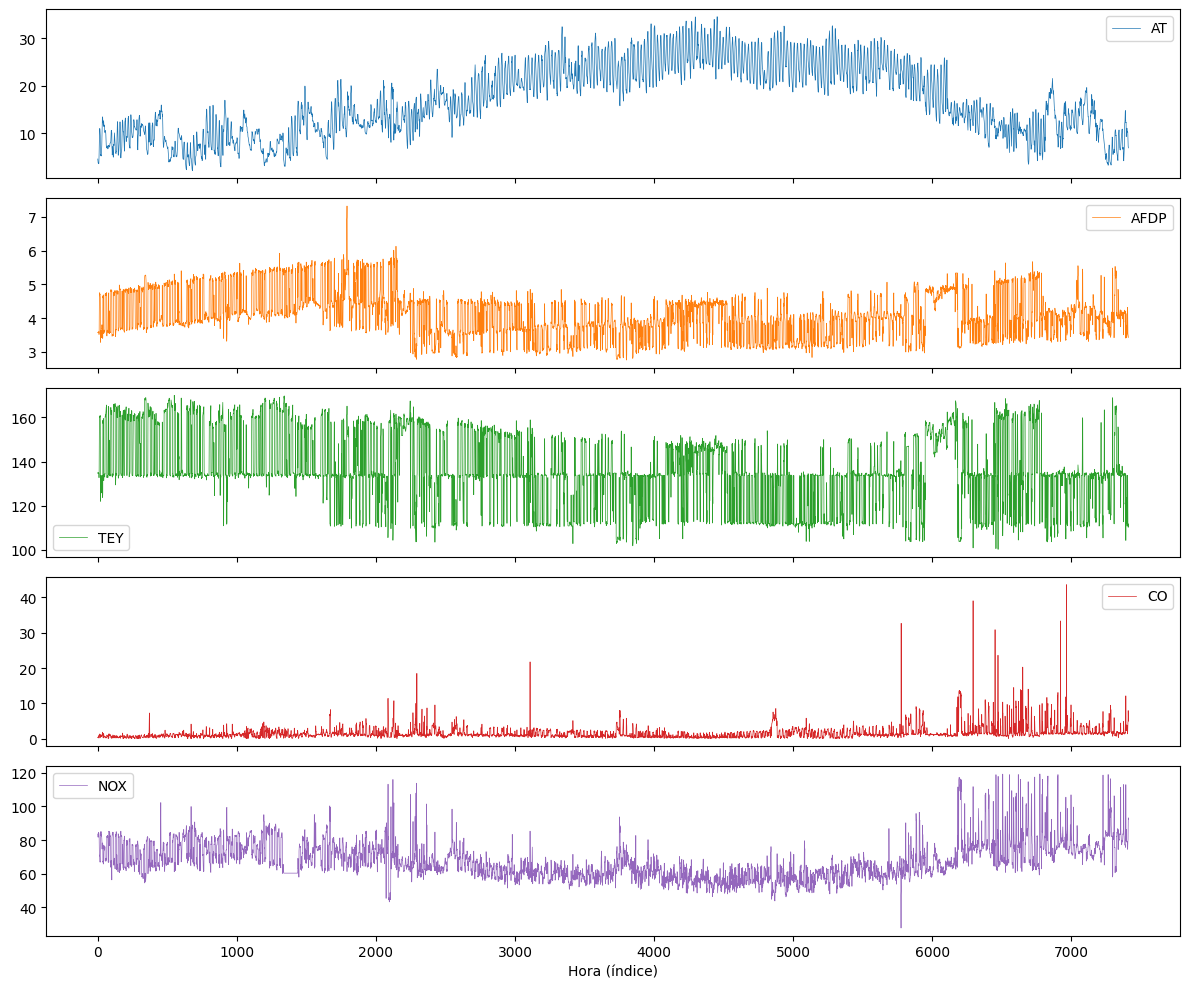

In [26]:
df_gt[["AT", "AFDP", "TEY", "CO", "NOX"]].plot(
    subplots=True, figsize=(12, 10), sharex=True, linewidth=0.5
)
plt.xlabel("Hora (índice)")
plt.tight_layout()
plt.show()

In [27]:
print(f"Humedad relativa > 100 %: {(df_gt['AH'] > 100).sum()} registros")
print(f"CO > 20 mg/m³: {(df_gt['CO'] > 20).sum()} registros")

# Valores de NOX idénticos al registro anterior: señal de sensor congelado
repetido = df_gt["NOX"].diff() == 0
print(f"NOX igual al registro anterior: {repetido.sum()} registros")
df_gt.loc[repetido, "NOX"].value_counts().head()

Humedad relativa > 100 %: 83 registros
CO > 20 mg/m³: 8 registros
NOX igual al registro anterior: 105 registros


,count
NOX,
60.380,101
64.113,1
53.980,1
60.373,1
74.173,1


**¿Qué observamos?**

- `AT` muestra el ciclo estacional (invierno → verano) y el ciclo día-noche: confirma que las filas están en orden cronológico.
- `AFDP` aumenta gradualmente y luego cae bruscamente: el filtro de aire se ensucia y luego se limpia o se reemplaza. Es un cambio en el estado del equipo a lo largo del tiempo.
- `TEY` no varía de forma continua: se concentra en algunos niveles (lo analizamos a continuación).
- `CO` tiene picos aislados, que pueden ser físicos (combustión incompleta en transitorios o a carga baja). En cambio, `NOX` permanece congelado en un mismo valor durante muchas horas: eso sí es un problema de calidad, incluso en un dataset publicado.

Como no usaremos `CO` ni `NOX` para predecir la potencia, no los limpiaremos aquí. Sí sería imprescindible hacerlo si quisiéramos modelar las emisiones.

### 3.2 Regímenes de carga

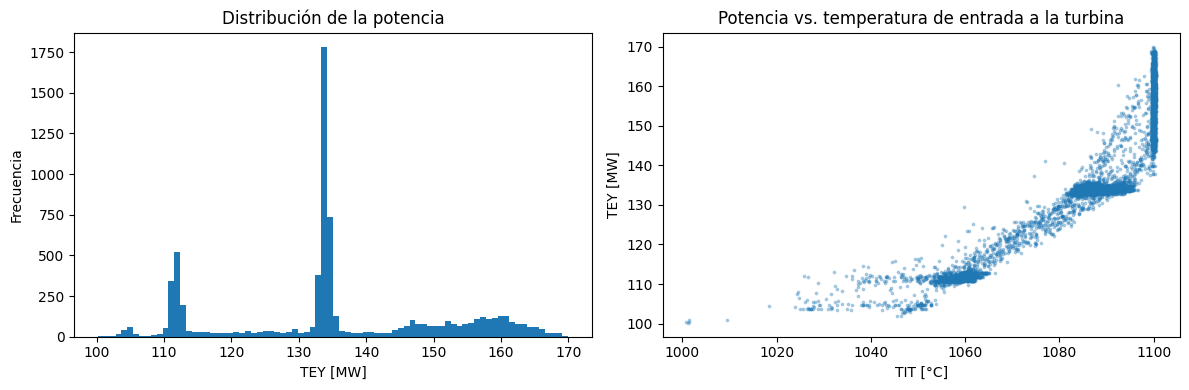

In [28]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

ejes[0].hist(df_gt["TEY"], bins=80)
ejes[0].set_xlabel("TEY [MW]")
ejes[0].set_ylabel("Frecuencia")
ejes[0].set_title("Distribución de la potencia")

ejes[1].scatter(df_gt["TIT"], df_gt["TEY"], s=3, alpha=0.3)
ejes[1].set_xlabel("TIT [°C]")
ejes[1].set_ylabel("TEY [MW]")
ejes[1].set_title("Potencia vs. temperatura de entrada a la turbina")

plt.tight_layout()
plt.show()

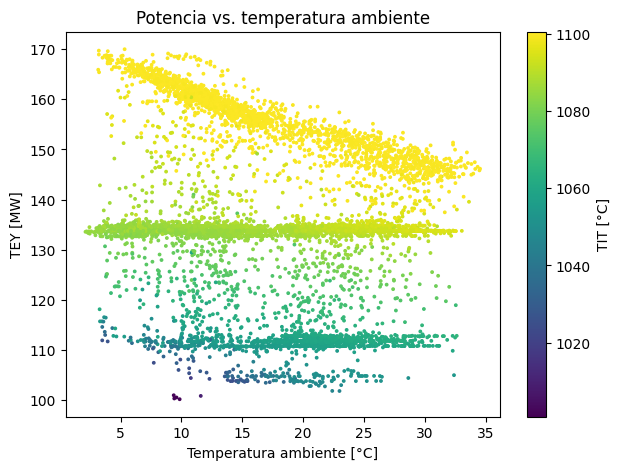

In [29]:
plt.figure(figsize=(7, 5))
plt.scatter(df_gt["AT"], df_gt["TEY"], c=df_gt["TIT"], s=3, cmap="viridis")
plt.colorbar(label="TIT [°C]")
plt.xlabel("Temperatura ambiente [°C]")
plt.ylabel("TEY [MW]")
plt.title("Potencia vs. temperatura ambiente")
plt.show()

**Interpretación física**

- La potencia se agrupa en niveles: la planta opera según el **despacho** (cuánta energía le pide la red), una decisión del operador.
- En el nivel más alto, `TIT` se mantiene en ~1100 °C: es el **límite de temperatura de los materiales** de la turbina. A esta condición se le llama **carga base**: el control mantiene la TIT en su máximo y la potencia queda determinada por el aire que entra al compresor.
- En carga base, la potencia **disminuye** al aumentar la temperatura ambiente: el aire caliente es menos denso (ρ = P/RT), entra menos masa de aire al compresor y se genera menos potencia.
- En carga parcial, la potencia la fija el operador: ninguna variable ambiental puede predecirla.

Separaremos entonces ambos regímenes usando la TIT.

In [30]:
UMBRAL_TIT = 1098  # °C; por encima consideramos que la turbina opera en carga base

df_gt["carga_base"] = df_gt["TIT"] >= UMBRAL_TIT

print(df_gt["carga_base"].value_counts().rename({True: "Carga base", False: "Carga parcial"}))

carga_base
Carga parcial    5249
Carga base       2162
Name: count, dtype: int64


### 3.3 Análisis de componentes principales (PCA)

El PCA combina las variables originales en nuevas variables (**componentes principales**) que concentran la mayor parte de la variabilidad de los datos. Es útil para **explorar** datos con muchas variables correlacionadas.

Como las variables tienen unidades y magnitudes distintas, primero se estandarizan (media 0, desviación estándar 1).

In [31]:
variables_pca = ["AT", "AP", "AH", "AFDP", "GTEP", "TIT", "TAT", "TEY", "CDP"]

pca = make_pipeline(StandardScaler(), PCA(n_components=2))
componentes = pca.fit_transform(df_gt[variables_pca])

varianza = pca.named_steps["pca"].explained_variance_ratio_
print(f"Varianza explicada: PC1 = {varianza[0]:.1%} | PC2 = {varianza[1]:.1%}")

# Peso de cada variable original en cada componente
pesos = pd.DataFrame(
    pca.named_steps["pca"].components_.T, index=variables_pca, columns=["PC1", "PC2"]
)
pesos.round(2)

Varianza explicada: PC1 = 59.5% | PC2 = 20.6%


,PC1,PC2
AT,-0.07,0.67
AP,0.10,-0.46
AH,-0.07,-0.53
AFDP,0.40,-0.05
GTEP,0.43,0.09
TIT,0.38,0.16
TAT,-0.35,0.11
TEY,0.43,-0.01
CDP,0.43,0.05


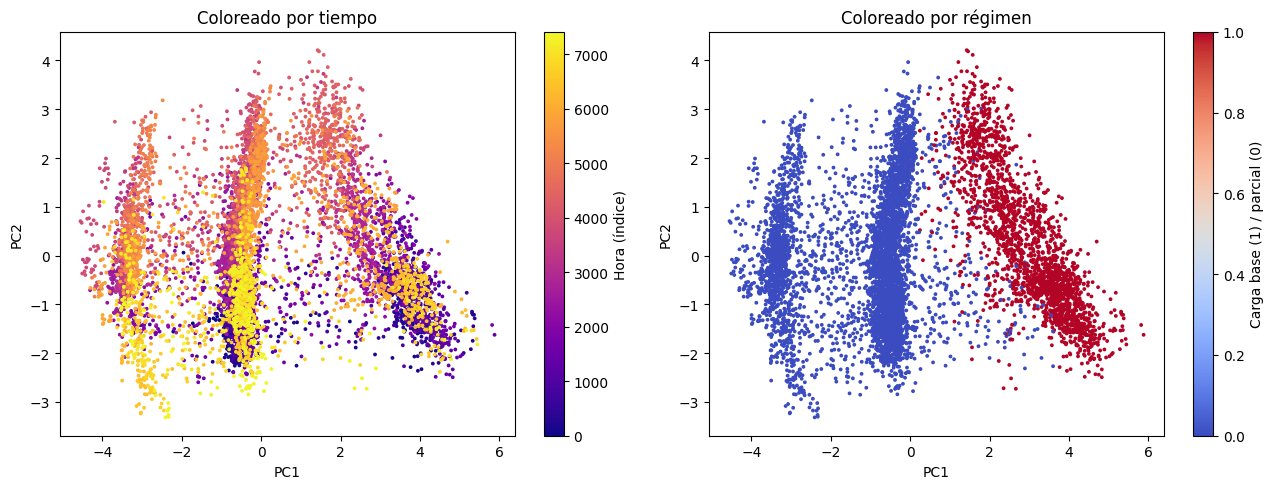

In [32]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 5))

graf = ejes[0].scatter(componentes[:, 0], componentes[:, 1], c=df_gt.index, s=3, cmap="plasma")
fig.colorbar(graf, ax=ejes[0], label="Hora (índice)")
ejes[0].set_title("Coloreado por tiempo")

graf = ejes[1].scatter(componentes[:, 0], componentes[:, 1], c=df_gt["carga_base"], s=3, cmap="coolwarm")
fig.colorbar(graf, ax=ejes[1], label="Carga base (1) / parcial (0)")
ejes[1].set_title("Coloreado por régimen")

for eje in ejes:
    eje.set_xlabel("PC1")
    eje.set_ylabel("PC2")
plt.tight_layout()
plt.show()

**Discusión**

- Observa qué variables tienen más peso en PC1: ¿qué representa físicamente esa combinación?
- ¿Se separan los regímenes de carga en el gráfico? ¿Se ve alguna evolución en el tiempo?
- El PCA **no** es un método para seleccionar variables:
  1. no elige variables, crea combinaciones de ellas;
  2. es no supervisado: trata TEY como una variable más, sin distinguirla como la variable que queremos predecir;
  3. las componentes no tienen un significado físico directo, y eso dificulta compararlas con modelos termodinámicos.

Lo usamos para **explorar**. La selección de variables la haremos con criterio físico.

### 3.4 Selección de variables: causa vs. consecuencia

Antes de elegir variables conviene preguntarse cuáles son **causas** de la potencia y cuáles son **consecuencias** del punto de operación:

- **Condiciones externas:** `AT`, `AP`, `AH`. No dependen de la planta.
- **Estado del equipo:** `AFDP` (ensuciamiento del filtro). Ojo: también depende en parte del flujo de aire.
- **Consecuencias del punto de operación:** `CDP`, `GTEP`, `TAT` y, en carga parcial, `TIT`. Se miden al mismo tiempo que la potencia y cambian junto con ella.

Separaremos los datos en el tiempo: el primer 75 % del año para entrenar y el último 25 % para probar.

In [33]:
corte = int(len(df_gt) * 0.75)
gt_ent = df_gt.iloc[:corte]
gt_prueba = df_gt.iloc[corte:]

print(f"Entrenamiento: {len(gt_ent)} horas | Prueba: {len(gt_prueba)} horas")

Entrenamiento: 5558 horas | Prueba: 1853 horas


Modelo A (todas las variables): MAE = 0.66 | RMSE = 0.89 | R² = 0.997


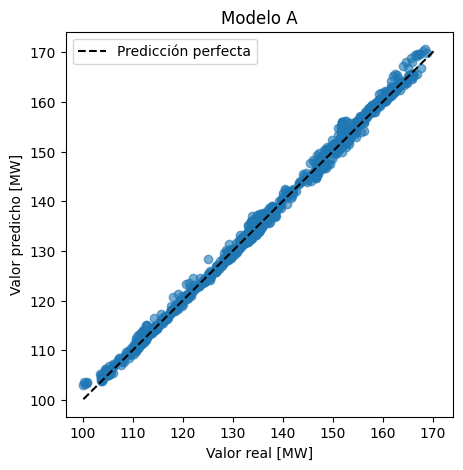

In [34]:
# Modelo A: todas las variables operativas, ambos regímenes
variables_A = ["AT", "AP", "AH", "AFDP", "GTEP", "TIT", "TAT", "CDP"]

modelo_A = LinearRegression().fit(gt_ent[variables_A], gt_ent["TEY"])
pred_A = modelo_A.predict(gt_prueba[variables_A])

evaluar_modelo(gt_prueba["TEY"], pred_A, "Modelo A (todas las variables)")
graficar_real_vs_pred(gt_prueba["TEY"], pred_A, "Modelo A", "[MW]")

**Discusión:** el modelo A es casi perfecto, pero ¿qué aprendimos? `CDP`, `GTEP`, `TIT` y `TAT` describen el mismo punto de operación que la potencia: predecir `TEY` con ellas es casi como medirla por otro camino. No sirve para anticipar la potencia, porque esas variables solo se conocen cuando la turbina ya está operando.

Esto no lo hace inútil: un modelo así puede funcionar como **sensor virtual**, para validar la medición de potencia o reemplazarla si el medidor falla.

Carga base · entrenamiento: 1667 horas | prueba: 495 horas
Promedio (referencia): MAE = 4.98 | RMSE = 6.00 | R² = -0.000
Regresión lineal: MAE = 2.23 | RMSE = 3.61 | R² = 0.638
Random forest: MAE = 2.98 | RMSE = 4.00 | R² = 0.555


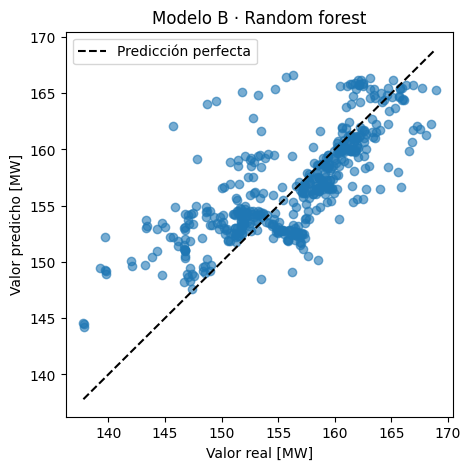

In [35]:
# Modelo B: solo carga base y variables que no dependen de la operación
variables_B = ["AT", "AP", "AH", "AFDP"]

base_ent = gt_ent[gt_ent["carga_base"]]
base_prueba = gt_prueba[gt_prueba["carga_base"]]
print(f"Carga base · entrenamiento: {len(base_ent)} horas | prueba: {len(base_prueba)} horas")

# Referencia: predecir siempre el promedio del entrenamiento
pred_media = np.full(len(base_prueba), base_ent["TEY"].mean())

lineal_B = LinearRegression().fit(base_ent[variables_B], base_ent["TEY"])
rf_B = RandomForestRegressor(n_estimators=200, random_state=SEMILLA, n_jobs=-1).fit(
    base_ent[variables_B], base_ent["TEY"]
)
pred_lineal_B = lineal_B.predict(base_prueba[variables_B])
pred_rf_B = rf_B.predict(base_prueba[variables_B])

evaluar_modelo(base_prueba["TEY"], pred_media, "Promedio (referencia)")
evaluar_modelo(base_prueba["TEY"], pred_lineal_B, "Regresión lineal")
evaluar_modelo(base_prueba["TEY"], pred_rf_B, "Random forest")
graficar_real_vs_pred(base_prueba["TEY"], pred_rf_B, "Modelo B · Random forest", "[MW]")

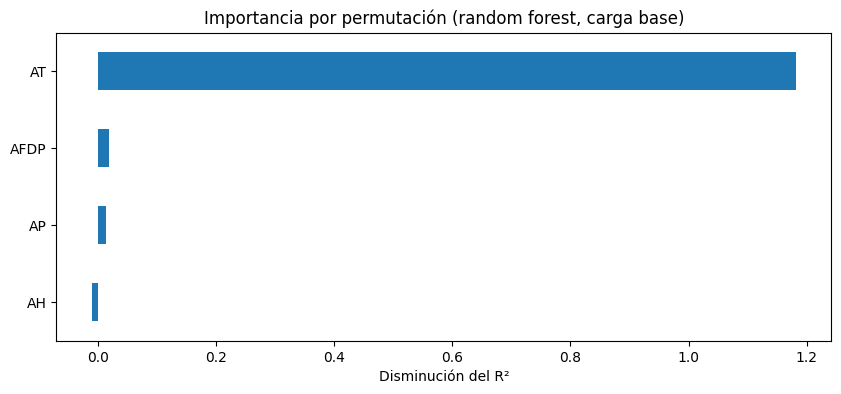

In [36]:
# Importancia por permutación: cuánto empeora el modelo si "desordenamos" una variable
importancia = permutation_importance(
    rf_B, base_prueba[variables_B], base_prueba["TEY"], n_repeats=10, random_state=SEMILLA
)
pd.Series(importancia.importances_mean, index=variables_B).sort_values().plot.barh(
    title="Importancia por permutación (random forest, carga base)"
)
plt.xlabel("Disminución del R²")
plt.show()

**Discusión**

- Compara ambos modelos con la referencia: un modelo solo es útil si mejora claramente respecto a predecir el promedio.
- ¿Qué variable es la más importante? ¿Coincide con la explicación física de la densidad del aire?
- La importancia por permutación se calcula con los datos de prueba y mide cuánto depende el modelo de cada variable, no su efecto causal. Si las variables están correlacionadas (AT, AP y AH cambian juntas con la estación), la importancia puede repartirse de forma engañosa. Una disminución mayor que el R² del modelo es posible: al desordenar AT, el R² se vuelve negativo.
- El R² del modelo B (0.64) parece mucho peor que el del modelo A (0.997), pero en carga base la potencia varía mucho menos: el R² depende de la variabilidad de los datos de prueba. Compara también el MAE en MW.

**Ejercicio 2:** quita `AFDP` de `variables_B` y vuelve a ejecutar. Luego agrega `CDP`. ¿Cómo cambian los resultados? ¿Por qué agregar `CDP` mejora tanto el modelo, y sería útil ese modelo para anticipar la potencia?

### 3.5 (Opcional) ¿Y una red neuronal?

Las redes neuronales requieren escalar las variables y ajustar más parámetros. Para datos tabulares con pocas variables, rara vez superan a modelos como el random forest.

In [37]:
red = make_pipeline(
    StandardScaler(),
    MLPRegressor(hidden_layer_sizes=(32, 16), max_iter=2000, random_state=SEMILLA),
)
red.fit(base_ent[variables_B], base_ent["TEY"])
pred_red = red.predict(base_prueba[variables_B])

evaluar_modelo(base_prueba["TEY"], pred_red, "Red neuronal (MLP)")

Red neuronal (MLP): MAE = 2.49 | RMSE = 3.90 | R² = 0.576


### Conclusiones del Set 2

1. Incluso un dataset publicado y "limpio" tiene problemas de calidad: unidades incorrectas, valores imposibles y sensores congelados.
2. Entender el proceso permite identificar regímenes de operación (carga base vs. parcial) y modelar solo donde la física lo permite.
3. Usar variables que son consecuencia del punto de operación da modelos "perfectos" pero con poco valor predictivo.
4. Un modelo más complejo (red neuronal) no garantiza mejores resultados.

## 4. Comparación con modelos termodinámicos

Comparamos los modelos de ML con modelos basados en balances de energía. Las propiedades del agua se calculan con la formulación industrial **IAPWS-97**, implementada en la librería `iapws`.

In [38]:
!pip install iapws -q

### 4.1 Set 1: turbina de extracción-condensación

Modelo de dos secciones: (1) de la entrada a la presión de extracción y (2) de la extracción al condensador, cada una con una eficiencia isentrópica. La potencia es:

P = [F_in·(h_in − h_ext) + (F_in − F_ext)·(h_ext − h_cond)]·η_gen = [F_in·(h_in − h_cond) − F_ext·(h_ext − h_cond)]·η_gen

Es **la misma estructura lineal** que aprendió la regresión de la Sección 2: P ≈ a·F_in − b·F_ext.

**Supuestos** (no hay mediciones para ellos): presiones manométricas, presión atmosférica de 1.01325 bar, condensador a 0.1 bar absolutos, eficiencia isentrópica de 0.80 en ambas secciones y eficiencia del generador de 0.97. La presión de extracción se fija en su mediana de operación con extracción, porque sin flujo la lectura no tiene sentido.

In [39]:
from iapws import IAPWS97  # unidades: P en MPa, T en K, h en kJ/kg, s en kJ/(kg·K)

P_ATM = 0.101325       # MPa, supuesto
P_COND = 0.010         # MPa (0.1 bar abs), supuesto
ETA_TURBINA = 0.80     # supuesto
ETA_GENERADOR = 0.97   # supuesto


def man_a_abs(p_kgcm2):
    """Convierte presión manométrica en kg/cm² a presión absoluta en MPa."""
    return p_kgcm2 * 0.0980665 + P_ATM


P_EXT = man_a_abs(df_limpio.loc[df_limpio["F_ext"] > 50, "P_ext"].median())


def entalpias(p_vapor, t_vapor):
    """Entalpías [kJ/kg] en la entrada, la extracción y el condensador."""
    entrada = IAPWS97(P=man_a_abs(p_vapor), T=t_vapor + 273.15)
    h_ext_s = IAPWS97(P=P_EXT, s=entrada.s).h
    h_ext = entrada.h - ETA_TURBINA * (entrada.h - h_ext_s)
    s_ext = IAPWS97(P=P_EXT, h=h_ext).s
    h_cond_s = IAPWS97(P=P_COND, s=s_ext).h
    h_cond = h_ext - ETA_TURBINA * (h_ext - h_cond_s)
    return entrada.h, h_ext, h_cond


def potencia_termodinamica(p_vapor, t_vapor, f_in, f_ext):
    """Potencia [MW] a partir del balance de energía; flujos en t/h."""
    h_in, h_ext, h_cond = entalpias(p_vapor, t_vapor)
    trabajo = f_in * (h_in - h_cond) - f_ext * (h_ext - h_cond)  # (t/h)·(kJ/kg)
    return trabajo / 3600 * ETA_GENERADOR  # 1 (t/h)·(kJ/kg) = 1/3600 MW

Modelo termodinámico: MAE = 3.52 | RMSE = 3.97 | R² = -0.407


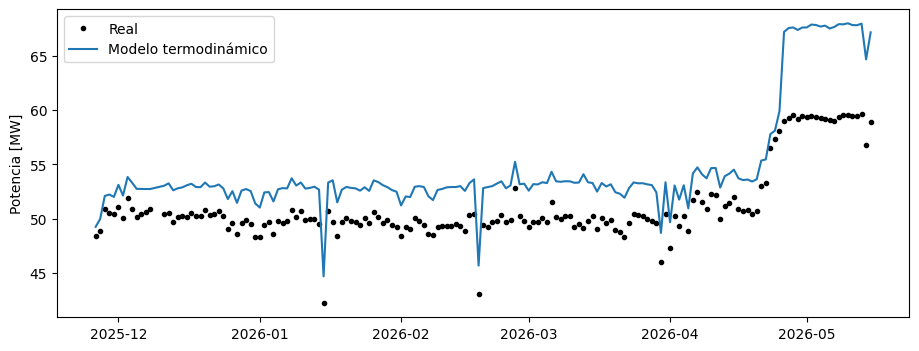

In [40]:
df_termo = df_limpio.copy()
df_termo["Potencia_termo"] = [
    potencia_termodinamica(fila.P_vapor, fila.T_vapor, fila.F_in, fila.F_ext)
    for fila in df_termo.itertuples()
]

evaluar_modelo(df_termo["Potencia"], df_termo["Potencia_termo"], "Modelo termodinámico")

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df_termo.index, df_termo["Potencia"], "k.", label="Real")
ax.plot(df_termo.index, df_termo["Potencia_termo"], "-", label="Modelo termodinámico")
ax.set_ylabel("Potencia [MW]")
ax.legend()
plt.show()

In [ ]:
termo_prueba = df_termo.loc[df_termo.index > FECHA_CORTE]
con_ext_t = termo_prueba["F_ext"] > 50
evaluar_modelo(termo_prueba["Potencia"], termo_prueba["Potencia_termo"], "Termodinámico · prueba")
evaluar_modelo(termo_prueba.loc[con_ext_t, "Potencia"], termo_prueba.loc[con_ext_t, "Potencia_termo"], "Termodinámico · con extracción")
evaluar_modelo(termo_prueba.loc[~con_ext_t, "Potencia"], termo_prueba.loc[~con_ext_t, "Potencia_termo"], "Termodinámico · sin extracción")

In [ ]:
# Sin extracción, P = a·F_in: los datos miden directamente el salto efectivo de F_in
sin_ext = df_limpio[df_limpio["F_ext"] < 1]
salto = (sin_ext["Potencia"] / sin_ext["F_in"]).median() * 3600
print(f"Salto efectivo medido (días sin extracción): {salto:.0f} kJ/kg")

In [41]:
# Comparación de los "saltos de entalpía efectivos" con los coeficientes de la regresión (Sección 2.5)
h_in, h_ext, h_cond = entalpias(df_limpio["P_vapor"].median(), df_limpio["T_vapor"].median())

print("Salto efectivo [kJ/kg]               Termodinámica   Regresión lineal")
print(f"F_in : (h_in − h_cond)·η_gen        {(h_in - h_cond) * ETA_GENERADOR:10.0f}   {modelo_lineal.coef_[0] * 3600:12.0f}")
print(f"F_ext: (h_ext − h_cond)·η_gen       {(h_ext - h_cond) * ETA_GENERADOR:10.0f}   {-modelo_lineal.coef_[1] * 3600:12.0f}")

Salto efectivo [kJ/kg]               Termodinámica   Regresión lineal
F_in : (h_in − h_cond)·η_gen              1080           1115
F_ext: (h_ext − h_cond)·η_gen              382            519


**Discusión**

- El modelo termodinámico depende de supuestos que no medimos (eficiencias, presión del condensador). ¿Sobreestima o subestima la potencia? ¿En qué régimen se equivoca más?
- La regresión estima los saltos de entalpía efectivos a partir de los datos, pero el coeficiente de F_in está mal determinado porque F_in casi no varía. Los días sin extracción lo miden directamente: compara ese valor con los dos modelos. Prueba cambiando P_COND: ¿qué valor reproduce la potencia con extracción y cuál sin extracción? ¿Por qué no es el mismo? (Pista: ¿cuánto vapor llega al condensador en cada régimen?)
- ML y termodinámica no compiten: la termodinámica da la **estructura** del modelo y los datos ayudan a **calibrar** lo que no se mide.

### 4.2 Set 2: ciclo Brayton ideal

Sin el flujo de aire no podemos calcular la potencia absoluta, pero sí la relación de compresión, la eficiencia y el trabajo específico del ciclo ideal en carga base. Dividiendo la potencia medida por el trabajo ideal obtenemos una estimación del **flujo de aire mínimo** (válida bajo los supuestos de aire estándar frío): el real es mayor, porque el trabajo real es menor que el ideal.

**Supuestos:** aire como gas ideal con k = 1.4 y cp = 1.005 kJ/(kg·K), y `CDP` como presión absoluta (si `CDP` fuera manométrica, r sería exactamente 1 unidad mayor).

In [42]:
K = 1.4      # cp/cv del aire, supuesto
CP = 1.005   # kJ/(kg·K), supuesto
a = (K - 1) / K

base = df_gt[df_gt["carga_base"]].copy()
base["r"] = base["CDP"] / (base["AP"] / 1000)   # CDP en bar, AP en mbar
base["eta_ideal"] = 1 - base["r"] ** (-a)

T1 = base["AT"] + 273.15   # entrada al compresor [K]
T3 = base["TIT"] + 273.15  # entrada a la turbina [K]
base["w_ideal"] = CP * T1 * ((T3 / T1) * (1 - base["r"] ** (-a)) - (base["r"] ** a - 1))  # kJ/kg
base["m_aire_min"] = base["TEY"] * 1000 / base["w_ideal"]  # kg/s

base[["r", "eta_ideal", "w_ideal", "m_aire_min"]].describe().T

,count,mean,std,min,25%,50%,75%,max
r,2162.0,13.498569,0.360275,12.192513,13.241947,13.563111,13.752507,14.479766
eta_ideal,2162.0,0.524536,0.003658,0.510573,0.521984,0.525246,0.527123,0.534034
w_ideal,2162.0,402.153917,8.743262,382.591279,394.291468,404.499999,409.104187,418.499153
m_aire_min,2162.0,387.534053,9.234157,353.254015,382.082375,388.570621,393.754887,412.107245


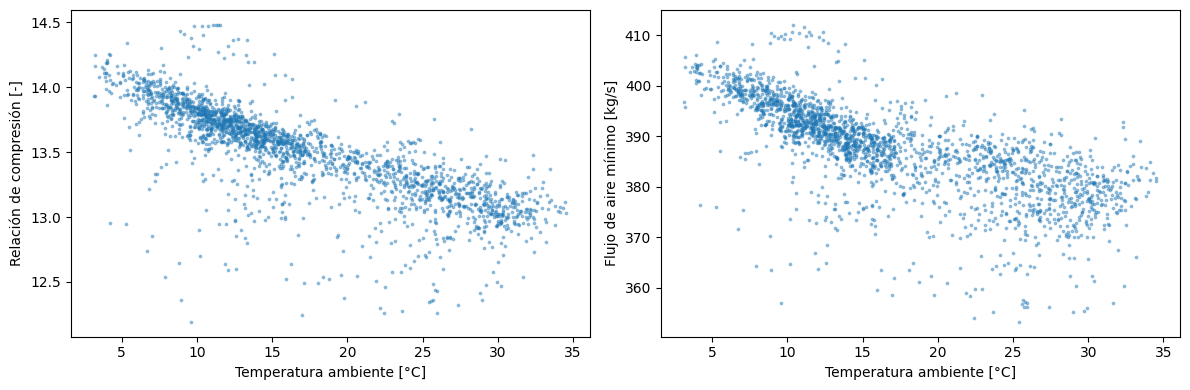

In [43]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

ejes[0].scatter(base["AT"], base["r"], s=3, alpha=0.4)
ejes[0].set_ylabel("Relación de compresión [-]")

ejes[1].scatter(base["AT"], base["m_aire_min"], s=3, alpha=0.4)
ejes[1].set_ylabel("Flujo de aire mínimo [kg/s]")

for eje in ejes:
    eje.set_xlabel("Temperatura ambiente [°C]")
plt.tight_layout()
plt.show()

**Discusión**

- La eficiencia del ciclo Brayton ideal es bastante mayor que la de una turbina de gas real en ciclo simple, típicamente 35–40 %. ¿Qué irreversibilidades explican la diferencia?
- ¿Cómo cambian la relación de compresión y el flujo de aire con la temperatura ambiente? ¿Es coherente con la explicación de la densidad del aire de la Sección 3.2?
- Sin medir el flujo de aire no podemos cerrar el balance de energía: el modelo termodinámico requiere datos que la planta no registra. Aquí los datos de operación (y el ML) complementan lo que la termodinámica no puede calcular por sí sola.

## 5. Conclusiones

1. **Mirar los datos primero:** graficar en el tiempo revela paradas, sensores congelados, cambios de régimen y errores de unidades que las estadísticas no muestran.
2. **La calidad de los datos limita al modelo:** ningún algoritmo compensa datos que no representan el proceso.
3. **La forma de evaluar importa:** la separación aleatoria puede ser muy optimista en procesos que evolucionan en el tiempo.
4. **El criterio físico guía las decisiones:** qué datos limpiar, qué regímenes separar y qué variables usar.
5. **Más complejo no es mejor**: los modelos simples con estructura física son interpretables y capturan la tendencia fuera del rango de entrenamiento, aunque la magnitud requiere calibración con datos.
6. **ML y termodinámica se complementan:** la física da la estructura y los datos calibran lo que no se mide.

### ¿Qué datos debería registrar una planta para hacer ML?

- **Marca de tiempo** en cada registro y frecuencia de muestreo conocida (idealmente horaria o mayor).
- Indicar si los datos son **instantáneos o promedios**, y registrar el estado de operación (encendido, parada, arranque).
- **Unidades documentadas**, incluyendo si las presiones son manométricas o absolutas.
- Variables que permitan cerrar balances: por ejemplo, condiciones del condensador o flujo de aire.
- Detección de **sensores congelados** o fuera de rango.

## Anexo: exportar el notebook a PDF

1. Ejecuta todas las celdas (*Entorno de ejecución → Ejecutar todas*) y guarda con `Ctrl + S`. Espera unos segundos a que se guarde.
2. En la celda siguiente, escribe en `NOMBRE_NOTEBOOK` el nombre exacto de tu copia, tal como aparece arriba a la izquierda, agregando `.ipynb`.
3. Ejecuta la celda y autoriza el acceso a tu Google Drive.
4. Se descargará un archivo `.html`. Ábrelo en tu navegador y usa `Ctrl + P → Guardar como PDF`.

In [45]:
import os
from google.colab import drive, files

# Nombre exacto de tu copia (agrega .ipynb al final)
NOMBRE_NOTEBOOK = "ML-IQ.ipynb"

drive.mount("/content/drive")
ruta = f"/content/drive/MyDrive/Colab Notebooks/{NOMBRE_NOTEBOOK}"

if os.path.exists(ruta):
    !jupyter nbconvert --to html "{ruta}" --output-dir /content
    files.download("/content/" + NOMBRE_NOTEBOOK.replace(".ipynb", ".html"))
else:
    print("No se encontró el archivo. Revisa el nombre en NOMBRE_NOTEBOOK.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[NbConvertApp] Converting notebook /content/drive/MyDrive/Colab Notebooks/ML-IQ.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 16 image(s).
[NbConvertApp] Writing 2433599 bytes to /content/ML-IQ.html


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>